# 02 · Inventario del Tema 1

Paso 2 de la descarga completa ([plan de la descarga](../../../docs/fase2/mercados_series/registro_descarga.md)).

## 0. Qué es este paso

**Cuenta lo que hay y fija las bases para decidir; no filtra nada.** Cada serie y cada fichero de precios del corpus
tiene una fila con sus metadatos y lo medido: fuente, frecuencia, historia, fiabilidad de la fecha de publicación,
redundancia y posibles fronteras con otros temas. El filtro («se queda / alias / fuera») es el paso 3.

Las tablas salen de dos órdenes y aquí solo se leen (solo metadatos y medidas, ningún valor de serie):

- `python -m ingesta.mercados_series inventario`: `inventario_series.csv`, `inventario_precios.csv`,
  `fiabilidad_c.csv` y `boe_rutas.csv` (módulo `inventario`);
- `python -m ingesta.mercados_series redundancia`: `redundancia_*.csv` y `tickers_sensibilidad.csv` (módulo
  `redundancia`).

Todas las cifras salen de las celdas de código; el texto no lleva ninguna escrita a mano. Los umbrales son las
constantes de los módulos, que se imprimen abajo: `CORTE_2000` (historia desde 2000), `MAX_PCT_ADELANTA`,
`MAX_ADELANTO_P05`, `MAX_ADELANTO_MARGEN`, `MAX_RETRASO_FIABLE` y `MIN_COMPARACIONES` (veredicto de una regla),
`UMBRAL_PROYECCION`, `UMBRAL_APERTURA` y `DIAS_DESLISTADO`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from ingesta.comun.rutas import resultados_dir
from ingesta.mercados_series import catalogo, inventario, universo, visibilidad

pd.set_option('display.max_rows', 40)
pd.set_option('display.max_colwidth', 70)
T = resultados_dir('mercados_series') / 'tablas'
inv = pd.read_csv(T / 'inventario_series.csv')
pre = pd.read_csv(T / 'inventario_precios.csv')
fia = pd.read_csv(T / 'fiabilidad_c.csv')
boe = pd.read_csv(T / 'boe_rutas.csv')
sens = pd.read_csv(T / 'redundancia_sensibilidad.csv')
conc = pd.read_csv(T / 'redundancia_conceptos.csv')
pares = pd.read_csv(T / 'redundancia_pares.csv')
bmw = pd.read_csv(T / 'redundancia_bm_weo.csv')
tick = pd.read_csv(T / 'tickers_sensibilidad.csv')
etf = pd.read_csv(T / 'redundancia_etf.csv')
PUBS = visibilidad.cargar_publicaciones()['publicadores']
LAGS = catalogo.cargar_lags()
CAT = catalogo.cargar_catalogo()
print(f'{len(inv):,} series ({inv["filas"].sum():,} filas) y {len(pre):,} ficheros de precios')
UMBRALES = ['CORTE_2000', 'MAX_PCT_ADELANTA', 'MAX_ADELANTO_P05', 'MAX_ADELANTO_MARGEN', 'MAX_RETRASO_FIABLE',
            'MIN_COMPARACIONES', 'UMBRAL_PROYECCION', 'UMBRAL_APERTURA', 'DIAS_DESLISTADO']
pd.DataFrame({'umbral': UMBRALES, 'valor_umbral': [str(getattr(inventario, u)) for u in UMBRALES]})

1,434 series (10,516,135 filas) y 1,471 ficheros de precios


,umbral,valor_umbral
0,CORTE_2000,2001-01-02 00:00:00
1,MAX_PCT_ADELANTA,5.0
2,MAX_ADELANTO_P05,1
3,MAX_ADELANTO_MARGEN,7
4,MAX_RETRASO_FIABLE,7
5,MIN_COMPARACIONES,20
6,UMBRAL_PROYECCION,0.5
7,UMBRAL_APERTURA,0.95
8,DIAS_DESLISTADO,30


## 1. Qué hay

Series por fuente y frecuencia:

In [2]:
pd.crosstab(inv['fuente'], inv['frecuencia'], margins=True, margins_name='total')

frecuencia,anual,diaria,mensual,semanal,trimestral,total
fuente,,,,,,
bce,0,48,3,0,1,52
bce_curvas,0,22,0,0,0,22
bis,0,0,18,0,17,35
boc,0,2,0,0,0,2
boc_curva,0,7,0,0,0,7
boe_curvas,0,12,0,0,0,12
boj,0,1,0,0,0,1
bundesbank,0,1,0,0,0,1
calculo_propio,0,8,0,0,1,9


Ficheros de precios por proveedor y clase (la del universo si el ticker está en él; si no, el tipo de Yahoo):

In [3]:
TIPOS_YAHOO = {'EQUITY': 'accion', 'ETF': 'etf', 'INDEX': 'indice', 'CURRENCY': 'divisa', 'FUTURE': 'futuro',
               'MUTUALFUND': 'fondo', 'CRYPTOCURRENCY': 'cripto'}
pre['clase_inv'] = pre['clase'].fillna(pre['tipo_yahoo'].map(TIPOS_YAHOO)).fillna('otro')
pd.crosstab(pre['clase_inv'], pre['proveedor'], margins=True, margins_name='total')

proveedor,coinbase,yahoo,total
clase_inv,,,
accion,0,1355,1355
cripto,2,0,2
divisa,0,4,4
etf,0,85,85
fondo,0,2,2
futuro,0,5,5
indice,0,15,15
otro,0,2,2
volatilidad,0,1,1


**Instrumentos del universo sin fichero de precios.** El universo (`config/universo.yaml`) es la lista de
instrumentos que pueden usar los agentes de cartera; muchos aún no se han descargado. Esta lista va al paso 3b.

In [4]:
u = universo.tabla_universo()
u['con_fichero'] = u['id'].isin(set(pre['id_universo'].dropna()))
sin = u[~u['con_fichero']]
etp = u['clase'].isin(['etf', 'etp'])
sin_yahoo = (~u['ticker_yahoo'].isin(set(pre.loc[pre['proveedor'] == 'yahoo', 'ticker']))).sum()
print(f'Universo: {len(u)} instrumentos; sin fichero de Yahoo: {sin_yahoo}; sin ningún fichero: {len(sin)} '
      '(la cripto tiene el de Coinbase)')
print(f'ETF/ETP: {etp.sum()}; sin precios {(~u.loc[etp, "con_fichero"]).sum()}, con precios {u.loc[etp, "con_fichero"].sum()}')
(sin.groupby(['clase', 'bucket'])['ticker_yahoo']
    .agg(n='size', ejemplos=lambda s: ', '.join(s.dropna().astype(str).head(5)))
    .reset_index().sort_values(['clase', 'n'], ascending=[True, False]))

Universo: 202 instrumentos; sin fichero de Yahoo: 134; sin ningún fichero: 132 (la cripto tiene el de Coinbase)
ETF/ETP: 145; sin precios 101, con precios 44


,clase,bucket,n,ejemplos
0,divisa,divisas,6,"JPY=X, CHF=X, CAD=X, AUDUSD=X, CNY=X"
23,etf,rv_emergentes,10,"EWZ, VWO, EWT, EWY, INDA"
28,etf,sector_eeuu,10,"SXLK.L, SXLF.L, SXLE.L, SXLV.L, SXLC.L"
15,etf,rf_gobierno_eeuu,6,"GOVT, IEI, EDV, IDTL.L, IBTM.L"
4,etf,factor_global,5,"IWMO.L, IWQU.L, MVOL.L, IWVL.L, IWSZ.L"
...,...,...,...,...
45,indice,rv_pais_g7,2,"^GSPTSE, FTSEMIB.MI"
42,indice,rv_asia_pacifico,1,^AXJO
43,indice,rv_eeuu,1,^DJI
46,volatilidad,volatilidad,4,"^VVIX, ^VIX3M, ^VXN, ^V2TX"


## 2. Historia desde 2000 (D1)

Una serie tiene historia desde 2000 (`desde_2000`) si su **primera publicación visible** (`fecha_publicacion`) es
anterior o igual a `CORTE_2000`. Se mide por la publicación y no por la referencia porque un dato de 1990 que se
publicó por primera vez en 2026 no existía para quien decidía en 2008: medir por la referencia daría por buena una
historia que el backtest no puede ver.

D1 y D2 se miden por separado: `desde_2000_exacto` exige además que la fecha **fiable** (exacta o contrastada con
ALFRED, `fiable_desde`) empiece antes del corte.

In [5]:
h = inv.groupby('fuente').agg(series=('id', 'size'), desde_2000=('desde_2000', 'sum'),
                              desde_2000_exacto=('desde_2000_exacto', 'sum'))
h.loc['total'] = h.sum()
h

,series,desde_2000,desde_2000_exacto
fuente,,,
bce,52,48,0
bce_curvas,22,0,0
bis,35,34,0
boc,2,0,0
boc_curva,7,0,0
boe_curvas,12,10,0
boj,1,1,0
bundesbank,1,1,0
calculo_propio,9,8,2


In [6]:
a = inv[(inv['nivel_fecha'] == 'A') & inv['desde_2000'] & ~inv['desde_2000_exacto']]
motivo = pd.Series('exacta más tarde, sin regla anterior', index=a.index)
motivo[a['regla_previa'].notna()] = 'ALFRED: regla previa antes del primer vintage'
motivo[a['regla_previa'].isna() & a['contrastada_desde'].notna()] = 'regla contrastada con ALFRED más tarde'
print(f'{len(a)} series A con historia desde 2000 cuya fecha fiable empieza después del corte:')
print(motivo.value_counts().to_string())
print('Su fecha fiable empieza, en mediana, en', pd.to_datetime(a['fiable_desde']).median().strftime('%Y-%m'))

100 series A con historia desde 2000 cuya fecha fiable empieza después del corte:
ALFRED: regla previa antes del primer vintage    80
regla contrastada con ALFRED más tarde           19
exacta más tarde, sin regla anterior              1
Su fecha fiable empieza, en mediana, en 2013-06


Estas series tienen historia desde 2000, pero hasta `fiable_desde` se fechan con una regla: el riesgo de ese tramo es
el veredicto de su regla (sección 3). Ejemplo típico: una serie de ALFRED con primer vintage en 2014 y una regla previa
que adelanta.

Tickers según la primera sesión (sin otros filtros), por clase:

In [7]:
ini = pd.to_datetime(pre['desde'])
t = pd.DataFrame({f'desde <= {c}': (ini <= c).groupby(pre['clase_inv']).sum()
                  for c in ('2001-01-02', '2008-01-02', '2017-01-02')})
t['total'] = pre.groupby('clase_inv').size()
t.loc['total'] = t.sum()
t

,desde <= 2001-01-02,desde <= 2008-01-02,desde <= 2017-01-02,total
clase_inv,,,,
accion,781,994,1166,1355
cripto,0,0,2,2
divisa,1,4,4,4
etf,18,42,53,85
fondo,2,2,2,2
futuro,5,5,5,5
indice,13,15,15,15
otro,0,0,2,2
volatilidad,1,1,1,1


## 3. Fiabilidad de la fecha (D2)

Cada serie lleva un **nivel** (`inventario.nivel_fecha`):

- **A**: tiene un tramo con fecha fiable desde `fiable_desde`: filas con fecha exacta (vintage exacto de ALFRED, WEO u
  OCDE, o cierre de mercado; `exacto_desde`) o una regla contrastada periodo a periodo con ALFRED y corregida fila a
  fila donde adelantaba (`contrastada_desde`). Antes de `fiable_desde` la serie se fecha con una regla.
- **B**: sin tramo fiable; regla (calendario, retraso fijo o fichero) verificada en el catálogo, en su publicador o en
  su retraso.
- **C**: sin tramo fiable; regla sin verificar.
- **D**: sin fecha de publicación.
- Una **derivada** (diferencia de dos series) toma el peor nivel de sus componentes.

Un ejemplo real de cada nivel:

In [8]:
preferidas = {'A': ['fred:PAYEMS', 'fred:GS10', 'oecd:CP.DEU', 'imf:WEO.DEU.PCPIPCH'], 'B': ['fred:DGS10'],
              'C': ['ecb:EXR.D.USD.EUR'], 'D': []}
filas = []
for nivel, ids in preferidas.items():
    cand = inv[inv['nivel_fecha'] == nivel]
    if cand.empty:
        print(f'Nivel {nivel}: ninguna serie de la base')
        continue
    elegidas = cand[cand['id'].isin(ids)]
    filas.append(elegidas if len(elegidas) else cand.head(1))
pd.concat(filas)[['nivel_fecha', 'id', 'metodo_publicacion', 'clave_regla', 'exacto_desde', 'contrastada_desde',
                  'fiable_desde', 'desde_2000_exacto', 'n_vintages']]

Nivel D: ninguna serie de la base


,nivel_fecha,id,metodo_publicacion,clave_regla,exacto_desde,contrastada_desde,fiable_desde,desde_2000_exacto,n_vintages
324,A,fred:GS10,lag_fijo,GS10,NaN,1996-12-03,1996-12-03,True,1
372,A,fred:PAYEMS,vintage_exacto,PAYEMS,1955-05-06,1955-05-06,1955-05-06,True,911
563,A,imf:WEO.DEU.PCPIPCH,vintage_exacto,NaN,2026-10-13,NaN,2026-10-13,False,1
762,A,oecd:CP.DEU,vintage_exacto,NaN,1999-03-01,NaN,1999-03-01,True,312
278,B,fred:DGS10,calendario,fed_h15,NaN,NaN,NaN,False,1
114,C,ecb:EXR.D.USD.EUR,calendario,ecb_fx,NaN,NaN,NaN,False,1


Matices del nivel A:

- **OCDE**: «vintage exacto» por edición, pero la fecha de cada edición es conservadora (el fin del mes de la edición):
  en la práctica es una regla conservadora, que retrasa y no adelanta.
- **WEO**: A con una sola edición (la última): la fecha es exacta, pero no hay historia publicada antes (sección 4).
- **ALFRED con regla previa** y **contrastadas**: A desde `fiable_desde`; antes, regla.

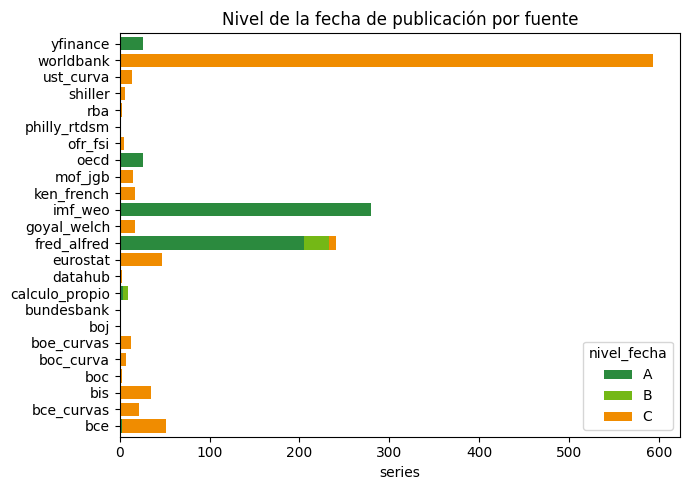

nivel_fecha,A,B,C,total
fuente,,,,
bce,3,0,49,52
bce_curvas,0,0,22,22
bis,0,0,35,35
boc,0,0,2,2
boc_curva,0,0,7,7
boe_curvas,0,0,12,12
boj,0,0,1,1
bundesbank,0,0,1,1
calculo_propio,4,5,0,9


In [9]:
n = pd.crosstab(inv['fuente'], inv['nivel_fecha'], margins=True, margins_name='total')
ax = n.drop('total').drop(columns='total').plot.barh(stacked=True, figsize=(7, 5), width=0.8,
                                                      color=['#2b8a3e', '#74b816', '#f08c00', '#c92a2a'])
ax.set_xlabel('series'); ax.set_ylabel(''); ax.set_title('Nivel de la fecha de publicación por fuente')
plt.tight_layout(); plt.show()
n

### Las reglas: B y C con el mismo tratamiento

Para cada regla se compara la fecha que da con una fecha real, donde la hay (`fiabilidad_c.csv`): la primera vintage
de ALFRED (reglas previas, periodo a periodo, y reglas de FRED contrastadas) y las ediciones archivadas de las
académicas. **Desvío = fecha de la regla − fecha real.** Negativo: la regla **adelanta** (deja ver el dato antes de
publicarse: riesgo de ver el futuro). Positivo: **retrasa** (conservadora). Veredicto (`inventario.veredicto_regla`):

- **no fiable**: adelanta en más del `MAX_PCT_ADELANTA` % de los casos, el percentil 5 del desvío adelanta más de
  `MAX_ADELANTO_P05` día o el mayor adelanto pasa de `MAX_ADELANTO_MARGEN` días;
- **fiable con margen**: adelanta alguna vez, sin pasar esos topes, o retrasa más de `MAX_RETRASO_FIABLE` días en
  mediana;
- **fiable**: nunca adelanta y retrasa poco;
- **no medible**: no hay con qué comparar. **No es lo mismo que «no fiable»**: no se sabe.

La regla solo importa **fuera del tramo fiable**. Por eso el veredicto que cuenta es el de la ventana desde 2000
(`veredicto_desde_2000`): una regla «no fiable» cuyas series están todas contrastadas o exactas desde antes de 2001 queda
«sin riesgo desde 2000». Es igual para B que para C.

In [10]:
fia.groupby(['nivel', 'veredicto', 'veredicto_desde_2000']).agg(
    reglas=('regla', 'size'), series=('n_series', 'sum'), series_sin_tramo_fiable=('n_series_c', 'sum'),
    series_sin_riesgo_2000=('n_series_sin_riesgo_2000', 'sum'))

reglas  series  \
nivel veredicto         veredicto_desde_2000                    
B     fiable            fiable                      1       2   
      no fiable         no fiable                   3      12   
C     fiable            fiable                      4       4   
      fiable con margen fiable con margen          11      41   
                        sin riesgo desde 2000       3       6   
      no fiable         no fiable                  57     150   
                        sin riesgo desde 2000      14      29   
      no medible        no medible                 27     801   

                                               series_sin_tramo_fiable  \
nivel veredicto         veredicto_desde_2000                             
B     fiable            fiable                                       0   
      no fiable         no fiable                                    0   
C     fiable            fiable                                       0   
      fiable con margen fiable con margen                           24   
                        sin riesgo desde 2000                        0   
      no fiable         no fiable                                   31   
                        sin riesgo desde 2000                        0   
      no medible        no medible                                 801   

                                               series_sin_riesgo_2000  
nivel veredicto         veredicto_desde_2000                           
B     fiable            fiable                                      0  
      no fiable         no fiable                                   0  
C     fiable            fiable                                      0  
      fiable con margen fiable con margen                           3  
                        sin riesgo desde 2000                       6  
      no fiable         no fiable                                  34  
                        sin riesgo desde 2000                      29  
      no medible        no medible                                  0

**No fiables en la ventana desde 2000** (la regla adelanta en un tramo sin contrastar). `n_series_sin_riesgo_2000`
cuenta las que ya están cubiertas; el resto tiene riesgo entre 2000 y su `fiable_desde`.

In [11]:
nf = fia[fia['veredicto_desde_2000'] == 'no fiable'].sort_values('n_series', ascending=False)
nf[['regla', 'nivel', 'n_series', 'n_series_sin_riesgo_2000', 'n_comparaciones', 'pct_adelanta',
    'adelanto_p95_dias', 'adelanto_max_dias']].reset_index(drop=True).head(25)

,regla,nivel,n_series,n_series_sin_riesgo_2000,n_comparaciones,pct_adelanta,adelanto_p95_dias,adelanto_max_dias
0,CPIAUCSL,C,35,3,2474,0.04,17.00,17.0
1,UNRATE,C,15,10,7255,0.33,19.00,19.0
2,BEA_RENTA_GASTO,C,9,7,3849,15.09,28.00,59.0
3,UMCSENT,C,8,2,667,4.35,16.80,26.0
4,fred_calculadas_dia_siguiente,B,5,0,14002,16.49,162.00,162.0
5,fred_tesoro_calculadas,B,5,0,15895,42.78,6.00,6.0
6,PPI_ALL_COMMODITIES,C,4,1,797,1.63,44.00,44.0
7,JOLTS,C,4,0,776,0.52,8.00,8.0
8,FED_Z1,C,4,1,292,1.71,12.80,14.0
9,INDPRO,C,4,2,2065,0.48,32.00,32.0


Las reglas **B** que salen no fiables son `moodys`, `fred_calculadas_dia_siguiente` y `fred_tesoro_calculadas`. Están
verificadas para el caso normal (el dato de D sale el hábil siguiente o el mismo día), pero ALFRED muestra días en que
FRED lo colgó más tarde (D+2, D+3) y apagones largos (Moody's no estuvo en FRED de octubre de 2016 a marzo de 2017),
que heredan los diferenciales que calcula FRED. Con el mismo tratamiento que las C: desde `contrastada_desde` la base
las corrige fila a fila; el riesgo queda en el tramo anterior.

In [12]:
b = fia[fia['nivel'] == 'B']
desde = pd.to_datetime(inv['contrastada_desde']).groupby(inv['clave_regla']).min().dt.strftime('%Y-%m-%d')
b = b.assign(contrastadas_desde=b['regla'].map(desde))
b[['regla', 'n_series', 'contrastadas_desde', 'pct_adelanta', 'adelanto_max_dias', 'veredicto_desde_2000']]

,regla,n_series,contrastadas_desde,pct_adelanta,adelanto_max_dias,veredicto_desde_2000
111,fred_calculadas_dia_siguiente,5,2014-01-27,16.49,162.0,no fiable
112,fred_tesoro_calculadas,5,2014-01-27,42.78,6.0,no fiable
115,moodys,2,2014-04-02,5.29,161.0,no fiable
116,nyfed_effr,2,2016-03-01,0.00,0.0,fiable


**No medibles**, por tipo de dato, con la regla que se aplica hoy (de `publicaciones.yaml` para los publicadores y de
`lags.yaml` para los retrasos). Las reglas con menos de `MIN_COMPARACIONES` comparaciones cuentan aquí también.

In [13]:
MERCADO = {'bce_curvas', 'ust_curva', 'mof_jgb', 'boe_curvas', 'boc_curva', 'boc', 'boj', 'bundesbank', 'rba'}
ACADEMICAS = {'ken_french', 'goyal_welch', 'shiller', 'datahub', 'ofr_fsi'}


def texto_regla(r):
    if r in PUBS:
        p = PUBS[r]
        dia = {'mismo': 'el mismo día', 'siguiente_habil': 'el hábil siguiente',
               'lunes_siguiente': 'el lunes siguiente'}[p['dia']]
        return f'{dia}, {p["hora"]:%H:%M} {p["huso"]}'
    if r in LAGS:
        return f'{LAGS[r]["lag"]} desde el fin de {LAGS[r]["fin_periodo"]}'
    return r


def tipo_dato(fuente, regla):
    if regla in PUBS or fuente in MERCADO:
        return 'mercado diario (curvas, tipos de cambio, €STR, OAS)'
    if fuente == 'worldbank':
        return 'anuales del Banco Mundial'
    if fuente in ('eurostat', 'bce', 'bis'):
        return 'macro de Eurostat, BCE y BIS'
    if fuente in ACADEMICAS:
        return 'académicas y ficheros'
    return 'otras de FRED'


poco = set(fia.loc[fia['n_comparaciones'] < inventario.MIN_COMPARACIONES, 'regla'])
inv['ventana'] = inv['veredicto_desde_2000']
inv.loc[inv['clave_regla'].isin(poco) & inv['ventana'].isin(['fiable', 'fiable con margen']), 'ventana'] = 'no medible'
nm = inv[inv['ventana'] == 'no medible'].copy()
nm['tipo_dato'] = [tipo_dato(f, r) for f, r in zip(nm['fuente'], nm['clave_regla'])]
(nm.groupby(['tipo_dato', 'clave_regla'])
   .agg(series=('id', 'size'), fuentes=('fuente', lambda s: ', '.join(sorted(set(s)))))
   .reset_index().assign(regla_hoy=lambda d: d['clave_regla'].map(texto_regla)))

,tipo_dato,clave_regla,series,fuentes,regla_hoy
0,académicas y ficheros,FF_MENSUAL,17,ken_french,45D desde el fin de mes
1,académicas y ficheros,GH_US10Y_MONTHLY,1,datahub,2M1D desde el fin de mes
2,académicas y ficheros,GW_ANUAL,17,goyal_welch,7M1D desde el fin de anio
3,académicas y ficheros,OFR_FSI,5,ofr_fsi,5D desde el fin de fecha
4,académicas y ficheros,SHILLER_DE,2,shiller,3M1D desde el fin de trimestre
5,académicas y ficheros,SHILLER_FICHERO,4,shiller,1M1D desde el fin de mes
6,académicas y ficheros,SP500_MONTHLY_DEEP_SRC,1,datahub,1M1D desde el fin de mes
7,anuales del Banco Mundial,WB_ANUAL,594,worldbank,12M desde el fin de anio
8,"macro de Eurostat, BCE y BIS",BIS_WS_CBPOL,9,bis,7D desde el fin de mes
9,"macro de Eurostat, BCE y BIS",BIS_WS_CREDIT_GAP,9,bis,6M desde el fin de trimestre


**Riesgo de cada grupo no medible:**

- **Mercado diario** (curvas oficiales, tipos de cambio y €STR del BCE, OAS de ICE en FRED): datos del día que el
  publicador cuelga el mismo día por la tarde o el hábil siguiente. Riesgo pequeño y acotado (un día si un festivo o un
  retraso no está en el calendario); no hay revisiones.
- **Anuales del Banco Mundial**: la regla (12 meses tras el fin del año) es holgada, pero los valores son los del último
  vintage: una revisión posterior se ve como si se hubiera conocido entonces (fuga de revisiones).
- **Macro de Eurostat, BCE y BIS**: retrasos fijos parecidos a los calendarios oficiales, sin medir; valores del último
  vintage (revisiones del PIB y del paro).
- **Académicas y ficheros** (Goyal-Welch, Shiller, Ken French, OFR, datahub): fechas de edición aproximadas y ficheros
  que se reeditan enteros; las ediciones archivadas no bastan para medir.
- **Otras de FRED** (recesiones del NBER, papel comercial antiguo): reglas especiales sin vintages.

**Propuesta por grupo, en la ventana desde 2000** (D2). Cada serie va a un grupo según su `veredicto_desde_2000`; lo no
medible, según su tipo de dato.

In [14]:
inv['grupo_d2'] = inv['ventana']
inv.loc[inv['ventana'] == 'no medible', 'grupo_d2'] = 'no medible: ' + nm['tipo_dato']
PROPUESTA = {
    'sin riesgo': ('entra', 'fecha exacta o contrastada en toda la ventana'),
    'exacta': ('entra', 'fecha exacta; su historia es cosa de D1'),
    'fiable': ('entra', 'regla medida que no adelanta'),
    'fiable con margen': ('entra', 'regla medida; con el margen medido si adelanta alguna vez'),
    'verificada sin medir': ('entra', 'regla B verificada para el caso normal'),
    'ver componentes': ('según componentes', 'derivada: hereda el peor de sus componentes'),
    'no fiable': ('quitar el tramo sin contrastar o regla conservadora',
                  'la regla adelanta entre 2000 y fiable_desde; conservadora = regla + adelanto máximo medido'),
    'no medible: mercado diario (curvas, tipos de cambio, €STR, OAS)': ('entra con aviso',
                                                                       'datos del día, regla de día siguiente o similar'),
    'no medible: anuales del Banco Mundial': ('a decidir (propuesta: con aviso)', 'regla holgada; revisiones; ver D9'),
    'no medible: macro de Eurostat, BCE y BIS': ('a decidir (propuesta: con aviso)',
                                                 'retrasos parecidos a los oficiales sin medir; último vintage'),
    'no medible: académicas y ficheros': ('a decidir (propuesta: con aviso)',
                                          'únicas con historia larga; fecha de edición aproximada'),
    'no medible: otras de FRED': ('a decidir', 'reglas especiales sin vintages; pocas series'),
}
prop = inv.groupby('grupo_d2').agg(series=('id', 'size'), B=('nivel_fecha', lambda s: (s == 'B').sum()),
                                   C=('nivel_fecha', lambda s: (s == 'C').sum()),
                                   con_historia_2000=('desde_2000', 'sum')).reset_index()
prop['propuesta'] = prop['grupo_d2'].map(lambda g: PROPUESTA.get(g, ('a decidir', ''))[0])
prop['motivo'] = prop['grupo_d2'].map(lambda g: PROPUESTA.get(g, ('', ''))[1])
prop.sort_values('series', ascending=False).reset_index(drop=True)

,grupo_d2,series,B,C,con_historia_2000,propuesta,motivo
0,no medible: anuales del Banco Mundial,594,0,594,548,a decidir (propuesta: con aviso),regla holgada; revisiones; ver D9
1,exacta,311,0,0,2,entra,fecha exacta; su historia es cosa de D1
2,"no medible: mercado diario (curvas, tipos de cambio, €STR, OAS)",132,0,132,82,entra con aviso,"datos del día, regla de día siguiente o similar"
3,no fiable,128,0,31,97,quitar el tramo sin contrastar o regla conservadora,la regla adelanta entre 2000 y fiable_desde; conservadora = regla ...
4,sin riesgo,115,0,0,115,entra,fecha exacta o contrastada en toda la ventana
5,"no medible: macro de Eurostat, BCE y BIS",53,0,52,48,a decidir (propuesta: con aviso),retrasos parecidos a los oficiales sin medir; último vintage
6,no medible: académicas y ficheros,47,0,47,47,a decidir (propuesta: con aviso),únicas con historia larga; fecha de edición aproximada
7,verificada sin medir,28,28,0,20,entra,regla B verificada para el caso normal
8,fiable con margen,13,0,0,9,entra,regla medida; con el margen medido si adelanta alguna vez
9,ver componentes,7,5,0,6,según componentes,derivada: hereda el peor de sus componentes


## 4. Proyecciones (D4)

Proyecciones: las del SEP del FOMC (el catálogo las declara previsión) y los horizontes del WEO (`.PROY.` en el id).
Van a una tabla aparte, fuera de la base curada.

In [15]:
print('Proyecciones por fuente:', inv.loc[inv['es_proyeccion'], 'fuente'].value_counts().to_dict())
w = inv[(inv['fuente'] == 'imf_weo') & ~inv['es_proyeccion']]
print(f'WEO que no son proyección: {len(w)}; con historia desde 2000 (D1): {w["desde_2000"].sum()}; '
      f'vintages: {sorted(int(x) for x in w["n_vintages"].unique())}; primera publicación: {sorted(w["pub_desde"].unique())}')

Proyecciones por fuente: {'imf_weo': 240, 'fred_alfred': 3}
WEO que no son proyección: 40; con historia desde 2000 (D1): 0; vintages: [1]; primera publicación: ['2026-10-13']


Las del WEO que no son proyección solo existen en la última edición: ninguna cumple D1. Para que sirvan hacen falta
las **ediciones antiguas del WEO** (paso 3b).

## 5. Redundancia (D8)

Un par de series es redundante si la correlación de sus cambios pasa del umbral en un periodo común de al menos N años.
Cada par se mide con cambios diarios y semanales, y se queda con la mayor (`base_correlacion`): la semanal evita que dos
fijaciones del mismo precio a horas distintas parezcan series distintas. Las series comparables son las no anuales que
tienen alguna pareja de su frecuencia.

In [16]:
s = sens[sens['fuente'] == 'total']
print(f'Series comparables (no anuales con pareja): {s["n_series_comparables"].iloc[0]} de {s["n_series_base"].iloc[0]}')
print('Pares por base de la correlación:', pares['base_correlacion'].value_counts().to_dict(),
      f'· dominados por valores atípicos: {pares["outlier_dominado"].sum()}')
s.pivot_table(index='umbral', columns='solape_min_anios',
              values=['n_alias_estrella', 'n_alias_transitivo', 'n_alias_estrella_entre_fuentes'])

Series comparables (no anuales con pareja): 557 de 1434
Pares por base de la correlación: {'diaria': 569, 'semanal': 120} · dominados por valores atípicos: 40


n_alias_estrella                \
solape_min_anios               3      5      10   
umbral                                            
0.90                        134.0  134.0  133.0   
0.95                        102.0  102.0  101.0   
0.98                         88.0   88.0   87.0   

                 n_alias_estrella_entre_fuentes              \
solape_min_anios                             3     5     10   
umbral                                                        
0.90                                       73.0  73.0  73.0   
0.95                                       59.0  59.0  59.0   
0.98                                       53.0  53.0  53.0   

                 n_alias_transitivo                
solape_min_anios                 3      5      10  
umbral                                             
0.90                          173.0  173.0  172.0  
0.95                          134.0  134.0  133.0  
0.98                           94.0   94.0   93.0

**Estrella frente a transitivo.** En cada grupo de series enlazadas se queda la de más historia; con la regla
**estrella** solo es alias la serie que se parece directamente a esa, mientras que la **transitiva** junta A y C porque
A~B y B~C aunque A y C no se parezcan. La recomendada es la estrella: no encadena parecidos y nunca da por duplicada una
serie que no se ha comparado con la que se queda.

El solape mínimo casi no cambia nada; el umbral sí. Por fuente, con 0,95 y 5 años:

In [17]:
f95 = sens[(sens['umbral'] == 0.95) & (sens['solape_min_anios'] == 5) & (sens['fuente'] != 'total')]
f95.sort_values('n_alias_estrella', ascending=False).head(8)[
    ['fuente', 'n_series_base', 'n_alias_estrella', 'n_alias_transitivo', 'pct_alias_estrella',
     'n_alias_estrella_entre_fuentes']].reset_index(drop=True)

,fuente,n_series_base,n_alias_estrella,n_alias_transitivo,pct_alias_estrella,n_alias_estrella_entre_fuentes
0,eurostat,47,31,31,66.0,20
1,fred_alfred,241,26,33,10.9,12
2,yfinance,26,12,18,46.2,10
3,ust_curva,14,6,10,42.9,6
4,bce_curvas,22,5,11,22.7,0
5,ken_french,17,5,5,29.4,1
6,goyal_welch,17,5,5,29.4,4
7,boc_curva,7,2,3,28.6,2


Buena parte de los alias son plazos vecinos de una misma curva o versiones de una misma serie de Eurostat: qué hacer con
ellos se decide en el paso 3 (fuente canónica). Los grupos de concepto más claros (mismo concepto y país en varias
fuentes, correlación mediana >= 0,98):

In [18]:
claros = conc[(conc['n_fuentes'] >= 2) & (conc['corr_mediana'] >= 0.98)]
print(f'{len(conc)} grupos de concepto; {len(claros)} claros entre fuentes')
claros.sort_values('n_miembros', ascending=False).head(15)[
    ['concepto', 'pais', 'n_miembros', 'fuentes', 'n_pares_base_semanal', 'corr_mediana']].reset_index(drop=True)

66 grupos de concepto; 38 claros entre fuentes


,concepto,pais,n_miembros,fuentes,n_pares_base_semanal,corr_mediana
0,inflacion_ipc,USA,9,eurostat; fred_alfred; goyal_welch; imf_weo; oecd; shiller; worldbank,0,0.981
1,inflacion_ipc,EA,9,bce; eurostat; oecd,0,0.992
2,bono_gobierno_10Y,USA,7,datahub; fred_alfred; shiller; ust_curva; yfinance,2,1.000
3,inflacion_ipc,ITA,6,eurostat; imf_weo; oecd; worldbank,0,0.986
4,inflacion_ipc,FRA,6,eurostat; imf_weo; oecd; worldbank,0,0.995
5,bono_gobierno_3M,USA,6,fred_alfred; goyal_welch; ust_curva; yfinance,5,0.999
6,paro,USA,5,eurostat; fred_alfred; imf_weo; oecd; worldbank,0,1.000
7,bono_gobierno_5Y,USA,4,fred_alfred; ust_curva; yfinance,2,1.000
8,paro,JPN,4,eurostat; imf_weo; oecd; worldbank,0,0.998
9,pib_real,EA,4,bce; eurostat,0,1.000


In [19]:
eu = pares[(pares['serie_a'] == 'ecb:EXR.D.USD.EUR') & (pares['serie_b'] == 'fred:DEXUSEU')]
eu[['serie_a', 'serie_b', 'pearson_diaria', 'pearson_semanal', 'base_correlacion', 'anios_solape']]

,serie_a,serie_b,pearson_diaria,pearson_semanal,base_correlacion,anios_solape
499,ecb:EXR.D.USD.EUR,fred:DEXUSEU,0.625,0.8979,semanal,27.73


**EURUSD del BCE frente a FRED: cerrado.** No es un desfase de fechas: es la hora de fijación (el BCE a las 14:15 CET,
FRED a mediodía de Nueva York). En cambios diarios las dos fijaciones se separan; en semanales se igualan.

## 6. Banco Mundial y WEO (D9)

Dos lecturas del alcance D3: **estricta** (G7, China y los agregados de la zona euro, mundial y emergentes) y
**ampliada** (además, los países miembros de la zona euro).

In [20]:
for nombre, dentro in (('estricta', bmw['en_alcance_estricto']),
                       ('ampliada', bmw['en_alcance_estricto'] | bmw['miembro_zona_euro'])):
    d, f = bmw[dentro], bmw[~dentro]
    dup = d[d['duplica_con_mayor_frecuencia']]
    queda = d[~d['duplica_con_mayor_frecuencia'] & ~d['es_proyeccion']]
    print(f'{nombre}: fuera {len(f)} series de {f["pais"].nunique()} países ({f["fuente"].value_counts().to_dict()}); '
          f'duplicadas con una de más frecuencia {dup["fuente"].value_counts().to_dict()}; '
          f'quedan {queda["fuente"].value_counts().to_dict()}, '
          f'{int(queda["cubre_2000_publicacion"].sum())} con historia desde 2000 por publicación')
AGREGADOS = {'WLD', 'EMU', 'EUU', 'LMY', 'EMDE', 'EME', 'OED', 'HIC', 'MIC'}
print('Agregados (zona euro, mundial, emergentes) en la base:', sorted(AGREGADOS & set(bmw['pais'])) or 'ninguno')

estricta: fuera 570 series de 207 países ({'worldbank': 570}); duplicadas con una de más frecuencia {'imf_weo': 20, 'worldbank': 20}; quedan {'imf_weo': 20, 'worldbank': 4}, 4 con historia desde 2000 por publicación
ampliada: fuera 516 series de 189 países ({'worldbank': 516}); duplicadas con una de más frecuencia {'imf_weo': 20, 'worldbank': 20}; quedan {'worldbank': 58, 'imf_weo': 20}, 58 con historia desde 2000 por publicación
Agregados (zona euro, mundial, emergentes) en la base: ninguno


Los agregados mundial y emergentes que pide D3 **no están en la base**: `fuentes/worldbank.py` descarta los agregados
regionales y por renta. Si se quieren, hay que añadirlos en el paso 3b.

## 7. Tickers (D10)

Cuántos tickers quedan según el inicio (`inicio_max`), la actividad (al menos el 90 % de las sesiones con volumen) y el
volumen mediano (`tickers_sensibilidad.csv`):

In [21]:
tt = tick[tick['desglose'] == 'total']
tt.pivot_table(index='inicio_max', columns=['filtro_sesiones_volumen_90', 'volumen_mediano_min'], values='n_quedan')

filtro_sesiones_volumen_90   False                              True           \
volumen_mediano_min             >0  >10000 >100000 sin_filtro      >0  >10000   
inicio_max                                                                      
2000                         816.0   811.0   776.0      821.0   749.0   745.0   
2007                        1055.0  1046.0  1001.0     1063.0   981.0   974.0   
2016                        1238.0  1226.0  1168.0     1250.0  1159.0  1149.0   

filtro_sesiones_volumen_90                     
volumen_mediano_min        >100000 sin_filtro  
inicio_max                                     
2000                         712.0      749.0  
2007                         931.0      981.0  
2016                        1093.0     1159.0

Por clase, sin filtro de actividad:

In [22]:
cl = tick[(tick['desglose'] == 'clase') & ~tick['filtro_sesiones_volumen_90']]
tabla = cl.pivot_table(index='grupo', columns=['inicio_max', 'volumen_mediano_min'], values='n_quedan')
tabla = tabla.loc[:, [(i, v) for i in (2000, 2016) for v in ('sin_filtro', '>0', '>100000')]]
tabla.columns = [f'inicio<={i} vol {v}' for i, v in tabla.columns]
tabla.join(cl.groupby('grupo')['n_total'].first()).astype(int)

,inicio<=2000 vol sin_filtro,inicio<=2000 vol >0,inicio<=2000 vol >100000,inicio<=2016 vol sin_filtro,inicio<=2016 vol >0,inicio<=2016 vol >100000,n_total
grupo,,,,,,,
accion,781,780,742,1166,1163,1101,1355
cripto,0,0,0,2,2,1,2
divisa,1,0,0,4,0,0,4
etf,18,18,18,53,53,48,85
fondo,2,1,0,2,1,0,2
futuro,5,5,4,5,5,4,5
indice,13,12,12,15,14,14,15
otro,0,0,0,2,0,0,2
volatilidad,1,0,0,1,0,0,1


El filtro de volumen se carga los índices, las divisas y la volatilidad, que no tienen volumen en Yahoo: esas clases
necesitan otra regla (solo inicio y huecos). ETF casi idénticos por correlación de las rentabilidades (con la misma
regla diaria o semanal que las series) y el par UCITS de referencia:

In [23]:
print(f'ETF/ETP del universo con precios: {u.loc[etp, "con_fichero"].sum()} de {etp.sum()} '
      '(con más ficheros se medirá mejor)')
etf[etf['tipo'].isin(['grupo', 'ucits'])][['tipo', 'id', 'miembros', 'buckets', 'base_correlacion', 'corr_diaria',
                                           'corr_semanal', 'corr_mediana']]

ETF/ETP del universo con precios: 44 de 145 (con más ficheros se medirá mejor)


,tipo,id,miembros,buckets,base_correlacion,corr_diaria,corr_semanal,corr_mediana
0,grupo,g1,IWD; JAVA,factor_eeuu,diaria,NaN,NaN,0.9809
1,grupo,g2,SPY; QUAL,factor_eeuu; rv_eeuu,diaria,NaN,NaN,0.9803
7,ucits,SPY~CSPX.L,SPY; CSPX.L,rv_eeuu,semanal,0.55,0.9094,0.9094


## 8. Banco de Inglaterra (D6)

Qué permite su `robots.txt` en la base estadística (IADB):

In [24]:
cb = boe[boe['tipo'] == 'candidata']
print('Rutas CSV/XML permitidas:', list(cb.loc[cb['uso'].str.startswith('permitida (CSV'), 'ruta']) or 'ninguna')
cb[['ruta', 'formato', 'permitida', 'uso']].reset_index(drop=True)

Rutas CSV/XML permitidas: ninguna


,ruta,formato,permitida,uso
0,/boeapps/database/_iadb-FromShowColumns.asp?csv.x=yes&SeriesCodes=...,csv,False,vetada
1,/boeapps/database/_iadb-FromShowColumns.asp?xml.x=yes&SeriesCodes=...,xml,False,vetada
2,/boeapps/database/fromshowcolumns.asp?Travel=NIxIRx&SeriesCodes=IU...,html,True,permitida solo en HTML (no es descarga CSV/XML): decisión del usuario
3,/boeapps/database/FromShowColumns.asp?Travel=NIxIRx&SeriesCodes=IU...,html,True,permitida solo en HTML (no es descarga CSV/XML): decisión del usuario
4,/boeapps/database/ShowChart.asp?SeriesCodes=IUDBEDR,html,False,vetada
5,/boeapps/database/Bank-Rate.asp,html,True,permitida solo en HTML (no es descarga CSV/XML): decisión del usuario
6,/boeapps/database/index.asp,html,True,permitida solo en HTML (no es descarga CSV/XML): decisión del usuario
7,/boeapps/iadb/FromShowColumns.asp?csv.x=yes&SeriesCodes=IUDBEDR,csv,False,vetada
8,/statistics/yield-curves,html,True,"permitida (curvas, ya descargadas)"
9,/-/media/boe/files/statistics/yield-curves/glcnominalddata.zip,zip,True,"permitida (curvas, ya descargadas)"


No hay ruta de descarga CSV ni XML; solo páginas HTML. La ficha `boe` sigue en `fallo` (el esquema común no tiene
«bloqueada») con el motivo en sus notas. Decisión del usuario: extraer de HTML o dejarlo (el tipo oficial del Reino
Unido ya llega por el BIS y las curvas del BoE ya están descargadas).

## 9. Fronteras con otros temas

Series que pueden solaparse con el Tema 2 (bancos centrales y riesgo sistémico) o el Tema 4 (noticias y
alternativos), para hablarlo con los compañeros antes del paso 3:

In [25]:
fr = inv[inv['posible_frontera'].notna()]
print(fr['posible_frontera'].value_counts().to_dict())
(fr.groupby(['posible_frontera', 'fuente'])['id']
   .agg(n='size', ejemplos=lambda s: ', '.join(s.head(3))).reset_index())

{'tema2': 122, 'tema4': 8}


,posible_frontera,fuente,n,ejemplos
0,tema2,bce,52,"ecb:DFR, ecb:EONIA, ecb:ESTR"
1,tema2,bce_curvas,22,"ecb:YC.AAA.10Y, ecb:YC.AAA.15Y, ecb:YC.AAA.1Y"
2,tema2,bis,35,"bis:WS_CBPOL.M.CA, bis:WS_CBPOL.M.CN, bis:WS_CBPOL.M.DE"
3,tema2,fred_alfred,8,"fred:ANFCI, fred:CFSI, fred:KCFSI"
4,tema2,ofr_fsi,5,"ofr:FSI, ofr:FSI_CREDIT, ofr:FSI_FUNDING"
5,tema4,eurostat,6,"eurostat:ei_bssi_m_r2.M.BS-ESI-I.SA.DE, eurostat:ei_bssi_m_r2.M.BS..."
6,tema4,fred_alfred,1,fred:UMCSENT
7,tema4,yfinance,1,yf:^SKEW


## 10. Decisiones para el usuario

- **D2 · fecha en la ventana desde 2000 (B y C igual):** entran «sin riesgo», «exacta», «fiable» y «con margen»; lo
  «no fiable» se quita en el tramo sin contrastar o pasa a regla conservadora; lo «no medible» de mercado diario entra
  con aviso; Banco Mundial, macro de Eurostat/BCE/BIS, académicas y otras de FRED, a decidir (propuesta: con aviso).
- **D8 · redundancia:** umbral 0,95 con la regla estrella y 5 años de solape.
- **D9 · Banco Mundial y WEO:** alcance estricto y fuera lo duplicado con una serie de más frecuencia.
- **D10 · tickers:** inicio <= 2016 para entrar, historia desde 2000 como preferencia y volumen solo en las clases que
  lo tienen (acciones, ETF, fondos, futuros).
- **D6 · BoE:** dejarlo; no extraer de HTML (sin CSV/XML permitido; Bank Rate por el BIS y curvas ya descargadas).
- **Paso 3b (lista inicial):** instrumentos del universo sin precios, ediciones antiguas del WEO, agregados mundial y
  emergentes del Banco Mundial y refresco de todo hasta hoy.